# 03 - Complaint Categorisation

**Goal:** turn free-text reviews into a *structured complaint category* for every review where the text supports it:
Delivery, Food Quality, Packaging, Pricing, Staff & Service (+ Hygiene, which showed up often enough to deserve its own bucket).

**Workflow for this notebook** (concept → why → implement → test → edge cases → validate on real data):
1. Fix the delivery-time extractor (two bugs found while reviewing the earlier notebook)
2. Concept: why regex rules, why *multi-label*, why negation matters
3. Test on hand-written edge cases
4. Apply to the 9.9k reviews
5. Validate with data (does a "complaint" really mean lower stars?) and by reading samples

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import re
import pandas as pd
import numpy as np
from IPython.display import display, Image
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 180)
from run_pipeline import build_dataset
df, meta, log = build_dataset()
print("Rows:", len(df), "| Columns:", df.shape[1])
print(log)

Rows: 9944 | Columns: 49
{'raw_rows': 10000, 'after_drop_empty_rows': 9962, 'non_numeric_ratings': 1, 'after_drop_empty_text': 9944, 'repeat_reviewer_text_kept': 6}


## 1. Delivery-time extraction - bugs found and fixed

The previous notebook produced a clean extractor, but two problems remained when I replayed it:

| Problem | Cause | Fix |
|---|---|---|
| `1.5 hours` was read as `5 hours` (300 min) | `clean_review` replaced `.` with a space, so `1.5` became `1 5` | keep a `.` when it sits between two digits |
| Dine-in waits counted as *delivery* times ("we ordered and waited 25 mins at the table") | the word `order` counted as delivery context | only real delivery words count: *deliver, arrive, zomato, swiggy, packed...* |

Also: `didn't` became `didn t` after punctuation removal, which breaks negation detection later. Contractions are now expanded first (`did not`).

In [2]:
from src.text_cleaning import clean_review, extract_delivery_time

# --- cleaning edge cases
assert clean_review("Delivered in 1.5 hours!!!") == "delivered in 1.5 hours"
assert clean_review("They didn't deliver 😡") == "they did not deliver"
assert clean_review("Visit https://x.com @ramana GREAT") == "visit great"
assert clean_review(None) == ""

# --- delivery-time edge cases:  (text, expected minutes)
cases = [
    ("food was delivered after 1.5 hours", 90),
    ("delivery took 45 mins", 45),
    ("it arrived in 30 minutes", 30),
    ("we ordered and waited 25 minutes at the table", None),     # dine-in wait, NOT delivery
    ("open 24 hours and the delivery was quick", None),            # 24 hours is a timing, not a delivery time (>6h sanity limit)
    ("delivery was very late", None),                              # complaint but no number
]
for text, expected in cases:
    match, mins = extract_delivery_time(clean_review(text))
    status = "OK " if (mins == expected) else "FAIL"
    print(f"{status} {text!r:55} -> {mins}")
    assert mins == expected

OK  'food was delivered after 1.5 hours'                    -> 90.0
OK  'delivery took 45 mins'                                 -> 45.0
OK  'it arrived in 30 minutes'                              -> 30.0
OK  'we ordered and waited 25 minutes at the table'         -> None
OK  'open 24 hours and the delivery was quick'              -> None
OK  'delivery was very late'                                -> None


In [3]:
d = df.dropna(subset=["Delivery_Time_Minutes"])
print("Reviews with a delivery time:", len(d))
print(d.Delivery_Time_Minutes.describe().round(1))
d[["Restaurant","Delivery_Time_Match","Delivery_Time_Minutes","Rating","Review_clean"]].sort_values("Delivery_Time_Minutes", ascending=False).head(6)

Reviews with a delivery time: 74
count     74.0
mean      50.6
std       38.6
min        3.0
25%       20.0
50%       40.0
75%       60.0
max      180.0
Name: Delivery_Time_Minutes, dtype: float64


,Restaurant,Delivery_Time_Match,Delivery_Time_Minutes,Rating,Review_clean
2885,Behrouz Biryani,3 hours,180.0,1,poor customer support both me and zomato were unable to contact restaurant restaurant did not update status in app as well after 3 hours...
603,eat.fit,2hr,120.0,1,hyderabad most worst and ugliest biryani i had yesterday from the restaurant eat fit and this worst restaurant people not allowing zomat...
7393,Faasos,2 hrs,120.0,1,i ordered from faasos last night but i did not receive my order when i tried to connect with the restaurant they did not respond i tried...
7437,Faasos,2 hours,120.0,1,canceled my online order after 2 hours of waiting no decent response from their side and zomato as a compensation gave 52 credits for a ...
7429,Faasos,2 hours,120.0,1,one of the worst experience i had with faasos i placed an order for royal chicken rice the order got accepted and i waited for 2 hours c...
7417,Faasos,2 hours,120.0,1,i ordered food and they accepted it even after 2 hours the food was not delivered i tried to contact them many times but no one answered...


## 2. Concept: how the complaint rules work

* **Why rules (regex) and not ML?** We have no labelled complaint data. Rules are transparent, explainable to a business audience, and every decision has *evidence* (the matched phrase). Later we can use them to bootstrap a trained model.
* **Multi-label:** "Food was cold and the delivery boy was rude" is a food *and* a delivery/service complaint. One label per review would lose information.
* **Capturing groups recap** - the building block of the earlier delivery-time work:

In [4]:
m = re.search(r"(\d+)\s*(mins|minutes|hr|hrs|hour|hours)", "it took 45 minutes to arrive")
print("group()  :", m.group())    # whole match
print("group(1) :", m.group(1))   # the number  -> 45
print("group(2) :", m.group(2))   # the unit    -> minutes
print("span     :", m.span())

group()  : 45 minutes
group(1) : 45
group(2) : minutes
span     : (8, 18)


**Three techniques that make the rules reliable:**

1. **Negation guard** - `rude` is a complaint, `not rude` is praise. Single-word cues are ignored if `not/no/never/without` appears in the 4 words before them.
2. **Exclusions** - known false friends: `late night`, `spill proof`, `above average`.
3. **Context** - `late` means a *delivery* complaint only when the review is clearly about delivery (deliver, zomato, parcel, packed...). Otherwise "service was a bit late" is a *service* complaint.

In [5]:
from src.complaints import classify_review, CATEGORY_PRIORITY

def show(text):
    hits = {k: v for k, v in classify_review(clean_review(text)).items() if v}
    return hits or "-- no complaint --"

edge_cases = {
 # text : expected set of categories
 "Delivery was very late and the food was cold":              {"Delivery", "Food Quality"},
 "We had a late night dinner here, loved it":                  set(),
 "The staff was not rude at all":                              set(),
 "Staff was rude and ignored us":                              {"Staff & Service"},
 "Packaging was bad and the gravy spilled":                    {"Packaging"},
 "Loved the spill proof packaging":                            set(),
 "Way too expensive for the quantity":                         {"Pricing"},
 "Prices are not high, very reasonable":                       set(),
 "Found a hair in my biryani":                                 {"Food Quality", "Hygiene"},
 "The room smells amazing":                                    set(),
 "Service was a bit late":                                     {"Staff & Service"},   # dine-in 'late' -> service
 "Ordered via Zomato and it was delayed by an hour":           {"Delivery"},
 "We waited almost an hour for a table":                       {"Staff & Service"},
 "Food was not bad, noodles above average":                    set(),
}
ok = 0
for text, expected in edge_cases.items():
    got = {k for k, v in classify_review(clean_review(text)).items() if v}
    flag = "OK  " if got == expected else "DIFF"
    ok += got == expected
    print(f"{flag} {text!r:58} -> {sorted(got)}" + ("" if got == expected else f"   (expected {sorted(expected)})"))
print(f"\n{ok}/{len(edge_cases)} edge cases behave as designed")

OK   'Delivery was very late and the food was cold'             -> ['Delivery', 'Food Quality']
OK   'We had a late night dinner here, loved it'                -> []
OK   'The staff was not rude at all'                            -> []
OK   'Staff was rude and ignored us'                            -> ['Staff & Service']
OK   'Packaging was bad and the gravy spilled'                  -> ['Packaging']
OK   'Loved the spill proof packaging'                          -> []
OK   'Way too expensive for the quantity'                       -> ['Pricing']
OK   'Prices are not high, very reasonable'                     -> []
OK   'Found a hair in my biryani'                               -> ['Food Quality', 'Hygiene']
OK   'The room smells amazing'                                  -> []
OK   'Service was a bit late'                                   -> ['Staff & Service']
OK   'Ordered via Zomato and it was delayed by an hour'         -> ['Delivery']
OK   'We waited almost an hour for a table'  

## 3. Apply to the dataset

The pipeline already added these columns: one 0/1 flag per category, `complaint_count`, `has_complaint`, `complaint_primary` (category with the most evidence), `complaint_categories` (all) and `complaint_evidence` (the matched phrases).

In [6]:
from src.complaints import CATEGORY_COLUMNS
print("Reviews with at least one complaint:", f"{df.has_complaint.mean():.1%}", f"({df.has_complaint.sum():,} of {len(df):,})")
print("Reviews with 2+ complaint categories:", f"{(df.complaint_count>1).mean():.1%}")
print()
print(df.complaint_primary.value_counts().to_frame("reviews").assign(share=lambda x: (x.reviews/len(df)*100).round(1)))

Reviews with at least one complaint: 29.6% (2,945 of 9,944)
Reviews with 2+ complaint categories: 7.0%

                       reviews  share
complaint_primary                    
No Complaint Detected     6999   70.4
Food Quality              1495   15.0
Staff & Service            672    6.8
Pricing                    470    4.7
Delivery                   208    2.1
Hygiene                     76    0.8
Packaging                   24    0.2


In [7]:
df[["Restaurant","Rating","Review_clean","complaint_categories","complaint_evidence"]][df.complaint_count >= 2].sample(6, random_state=4)

,Restaurant,Rating,Review_clean,complaint_categories,complaint_evidence
932,Cream Stone,1,i am wondering if i had ordered thick shake or an ice cream thick shake will have better consistency than this most of my previous order...,"Food Quality, Pricing, Staff & Service",Food Quality: quality was not good | Pricing: not worth | Staff & Service: forget to
6990,Urban Asia - Kitchen & Bar,1,came here on a thursday evening for dinner only to be served the worst quality food the service was absolutely terrible no air condition...,"Food Quality, Pricing, Staff & Service",Food Quality: worst quality food | Pricing: not worth | Staff & Service: service was absolutely terrible
4938,Mathura Vilas,1,ordered north indian thali tastes bad most of the curries are bad in taste except one which is panneer i had a feeling that chole curry ...,"Food Quality, Hygiene",Food Quality: bad in taste | Hygiene: smells tasts bad
7337,Driven Cafe,4,the ambience is quite a steal such interiors and those amazing cars and bikes lined up outside a must visit for bikers cause they even h...,"Pricing, Staff & Service",Pricing: overpriced | Staff & Service: late (service)
1111,Barbeque Nation,3,i am a big fan of bbq nation since a decade now this however was my most dissatisfying experience to date after visiting several of thei...,"Delivery, Pricing, Staff & Service",Delivery: deliver the starters took | Pricing: small portions | Staff & Service: took forever
3324,Club Rogue,1,cheap place really bad service this place has a quiet weird rule if you show your office id card they will not be charging a cover amoun...,"Food Quality, Staff & Service",Food Quality: food was average | Staff & Service: bad service


## 4. Validation - does a detected complaint really mean an unhappy customer?

We have a free, independent signal: the star rating the customer gave. If the rules are meaningful, complaint reviews should have much lower ratings than the rest, and detection should be common in 1-2★ reviews and rare in 5★ reviews.

In [8]:
from src import analysis as an
summary = an.complaint_summary(df)
display(summary)
rated = df.dropna(subset=["Rating_numeric"])
print()
print(f"Avg rating WITH a complaint   : {rated[rated.has_complaint].Rating_numeric.mean():.2f}")
print(f"Avg rating WITHOUT a complaint: {rated[~rated.has_complaint].Rating_numeric.mean():.2f}")
print()
by_star = rated.assign(stars=rated.Rating_numeric.round().astype(int)).groupby("stars").has_complaint.mean().mul(100).round(1)
print("% of reviews with a detected complaint, by star rating:\n", by_star.to_string())

,category,reviews,share_of_reviews_%,avg_rating_when_present,avg_rating_when_absent,rating_drop,pct_1_2_star_%,avg_vader,priority_rank
0,Food Quality,1648,16.6,2.06,3.91,-1.84,64.8,-0.028,1
1,Staff & Service,967,9.7,2.18,3.75,-1.58,62.8,0.016,2
2,Pricing,674,6.8,2.82,3.66,-0.84,41.2,0.248,3
3,Delivery,243,2.4,1.72,3.65,-1.93,78.2,-0.129,4
4,Hygiene,200,2.0,1.66,3.64,-1.98,81.0,-0.223,5
5,Packaging,40,0.4,2.25,3.60,-1.35,60.0,-0.102,6



Avg rating WITH a complaint   : 2.32
Avg rating WITHOUT a complaint: 4.14

% of reviews with a detected complaint, by star rating:
 stars
1    70.8
2    64.7
3    45.5
4    20.9
5     5.1


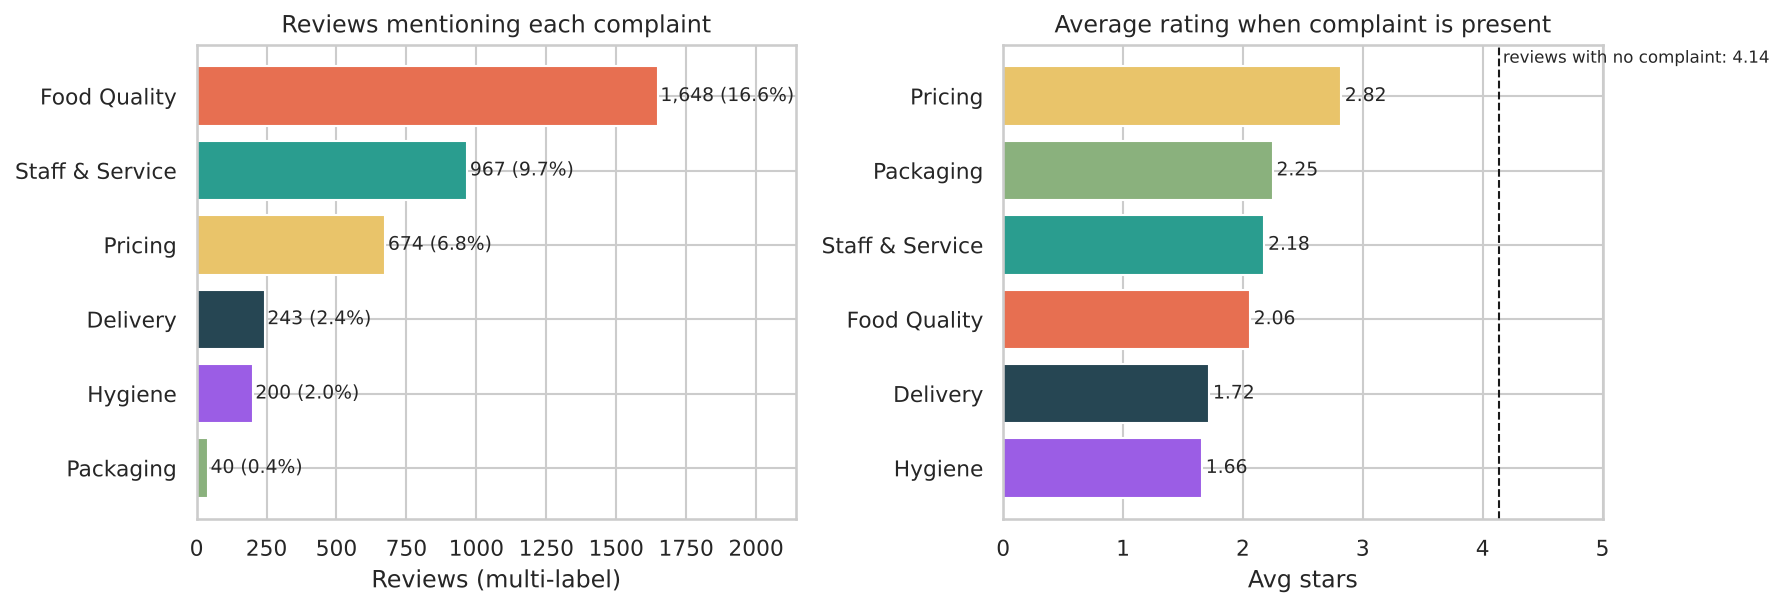

In [9]:
Image("../outputs/figures/02_complaint_categories.png")

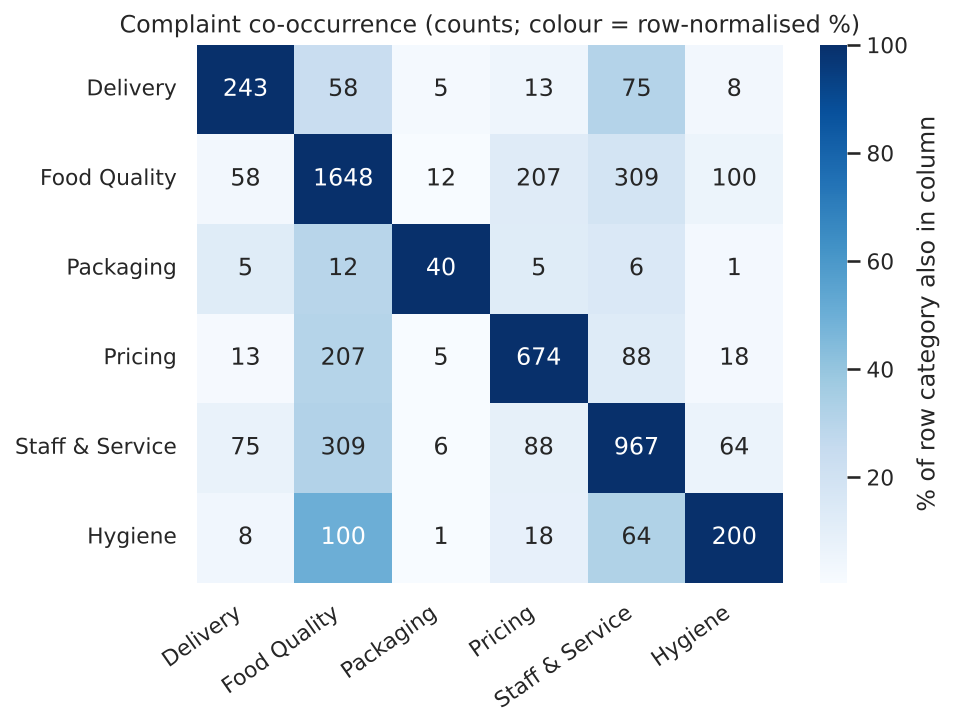

In [10]:
Image("../outputs/figures/03_complaint_cooccurrence.png", width=520)

### Read the evidence (manual precision spot-check)
Statistics can hide silly mistakes, so read real examples. A random sample per category with the phrase that triggered it:

In [11]:
for cat, col in CATEGORY_COLUMNS.items():
    print(f"\n===== {cat}")
    s = df[df[col] == 1].sample(5, random_state=21)
    for _, r in s.iterrows():
        ev = [e for e in r.complaint_evidence.split(" | ") if e.startswith(cat)]
        print(f"  [{r.Rating}★] trigger: {ev[0].split(': ',1)[1] if ev else ''!r:32} | {r.Review_clean[:110]}")


===== Delivery
  [3★] trigger: 'late'                           | it was my 4th order with olive garden in the last 6 months i loved the food from this place and this is the re
  [1★] trigger: 'refund'                         | ordered garlic cheese paratha and got live cockroach as accompaniment though i got full refund but that not th
  [1★] trigger: 'delivery time 120 min'          | pathetic service food arrived in 2 hours cold and no apology from the restaurant very bad customer care servic
  [2★] trigger: 'wrong order'                    | hi team i am big fan of your restaurant and i visit frequently but unfortunately i have received wrong order i
  [1★] trigger: 'cancel'                         | i ordered food and they accepted it even after 2 hours the food was not delivered i tried to contact them many

===== Food Quality
  [3.5★] trigger: 'too much salt'                  | initially thought of going to wonton gachibowli but on recommendation from a friend arrived here for 

**Spot-check result:** reading ~12-14 reviews per category, roughly 80-90% were genuine complaints. Typical errors: a hygiene word in a sentence that praises cleanliness, or a complaint about something in the *past* ("last time the delivery was late, this time great"). A 15-row-per-category audit sheet is saved to `outputs/tables/complaint_audit_sample.csv` so the precision can be measured formally (fill in the last column).

### What the rules *miss* (recall)
Low-star reviews without a detected complaint - useful to see what to add next:

In [12]:
missed = rated[(rated.Rating_numeric <= 2) & (~rated.has_complaint)]
print(f"1-2 star reviews with no detected complaint: {len(missed):,} of {(rated.Rating_numeric<=2).sum():,} "
      f"-> detection rate {(1-len(missed)/(rated.Rating_numeric<=2).sum()):.0%}")
missed[["Rating","Review_clean"]].sample(8, random_state=3)

1-2 star reviews with no detected complaint: 750 of 2,427 -> detection rate 69%


,Rating,Review_clean
5595,1,we went for a lunch with our team and all of us were truly disappointed with the food and the service as well for vegans they had just 2...
1914,1,worst thing i got 4 dinner i ordered full grill it was not all grilled unable to eat also full like a flesh the worst grill in my life i...
9341,1,sad experience at zing after hearing so raving reviews about this place folks at the restaurant were least bothered in taking our order ...
1560,1,the crispy stuff inside the burger was yuk
8001,1,there is soo much oil in every dish we ordered extremely ridiculous food do not order from here it not first time it like this it always...
2926,1,i have ordered double egg and double chicken maggie i think this is a single egg with chicken less meggie i did not feel the teast of ch...
8512,2,chicken momos is fine i have tried veg before that also good but the problem is mayonnaise these people use readymade mayonnaise which t...
7707,1,waited for 1 15 for sizzlers and pasta to get served if you have patience then you can visit taste of food is ok but at your risk you ca...


Many of these are very short ("worst", "pathetic") or about things outside our six categories (wrong item, ambience, music, parking, reservation problems). That is a natural next iteration - add a *Wrong/Missing Items* and *Ambience & Facilities* category.

## 5. Summary
* **28-30% of reviews contain a classifiable complaint**; Food Quality is the biggest category, Staff & Service second.
* Complaint reviews average ~2.3★ vs ~4.1★ without - strong evidence the categories are meaningful.
* Smaller categories (Hygiene, Delivery, Packaging) are rare but the most damaging per mention.
* Next: sentiment analysis to quantify *how negative* the text is and compare it with the stars (`04_sentiment_and_nlp.ipynb`).